In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import pandas as pd

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [2]:
from pathlib import Path

file_path = Path("../streams/val/stream_00.h5")

print("File tồn tại:", file_path.exists())
print("Đường dẫn:", file_path)

File tồn tại: True
Đường dẫn: ../streams/val/stream_00.h5


In [3]:
import h5py
import numpy as np

with h5py.File(file_path, "r") as f:
    cir = f["cir"][:]
    t = f["t"][:]
    radar_serials = f["radar_serials"][:]

print("Kích thước dữ liệu CIR:", cir.shape)
print("Kiểu dữ liệu CIR:", cir.dtype)
print("Kích thước mảng thời gian:", t.shape)
print("Mã số các radar:", radar_serials)

Kích thước dữ liệu CIR: (3, 88189, 368)
Kiểu dữ liệu CIR: float32
Kích thước mảng thời gian: (88189,)
Mã số các radar: [29171 29444 30722]


In [4]:
# Cấu trúc file HDF5 (các dataset và thuộc tính)
with h5py.File(file_path, "r") as f:
    print("Các key gốc:", list(f.keys()))
    f.visititems(lambda name, obj: print(f"{name:20s} shape={getattr(obj, 'shape', None)} dtype={getattr(obj, 'dtype', None)}")
                 if isinstance(obj, h5py.Dataset) else None)
    print("Thuộc tính của file:", dict(f.attrs))

Các key gốc: ['cir', 'radar_serials', 't']
cir                  shape=(3, 88189, 368) dtype=float32
radar_serials        shape=(3,) dtype=int32
t                    shape=(88189,) dtype=float64
Thuộc tính của file: {'fade_s': np.float64(0.2), 'seed': np.int64(2027), 'split': 'val', 'stream_index': np.int64(0)}


## 1. Giới thiệu tín hiệu CIR

CIR (*Channel Impulse Response*) là đáp ứng xung của kênh truyền, mô tả phản hồi của tín hiệu theo các khoảng cách tương ứng với đường truyền từ radar đến môi trường xung quanh. Khi môi trường hoặc vị trí của đối tượng thay đổi, tín hiệu phản xạ thu được cũng có thể thay đổi.

Trong bộ dữ liệu này, mỗi frame CIR chứa **368 range bins**. Có thể hiểu mỗi range bin là một ô khoảng cách trong biểu diễn tín hiệu radar. Giá trị CIR tại các bin cho biết đặc trưng tín hiệu phản hồi tương ứng với từng ô khoảng cách.

Dữ liệu được lưu với cấu trúc `cir[radar, frame, bin]`:

- `radar`: Chỉ số radar, tương ứng với một trong ba radar.
- `frame`: Chỉ số khung tín hiệu theo thời gian.
- `bin`: Chỉ số range bin, từ `0` đến `367`.

Ba radar có serial lần lượt là `29171`, `29444` và `30722`. Các frame được căn chỉnh trên lưới thời gian **50 Hz**, tương đương khoảng **0,02 giây mỗi frame**.

Trong phần phân tích này, tín hiệu CIR được trực quan hóa theo khoảng cách và thời gian. Tiếp theo, mức độ biến thiên giữa các frame được khảo sát bằng chỉ số **Motion Energy** nhằm tìm hiểu sự thay đổi của tín hiệu xung quanh thời điểm xảy ra sự kiện ngã.

## 2. Kiểm tra dữ liệu và trục thời gian

Kiểm tra số lượng frame, khoảng thời gian và mức độ biến thiên của trục thời gian trước khi tiến hành phân tích tín hiệu.

In [5]:
print("Số frame:", len(t))
print("Thời điểm đầu:", t[0])
print("Thời điểm cuối:", t[-1])
print("Khoảng thời gian:", t[-1] - t[0])
print("Khoảng cách giữa 5 frame đầu:", np.diff(t[:5]))

Số frame: 88189
Thời điểm đầu: 0.0
Thời điểm cuối: 1763.76
Khoảng thời gian: 1763.76
Khoảng cách giữa 5 frame đầu: [0.02 0.02 0.02 0.02]


In [6]:
# Kiểm tra frame CIR trùng hệt frame trước (so sánh trực tiếp dữ liệu CIR)
for r in range(cir.shape[0]):
    dup = np.all(cir[r, 1:] == cir[r, :-1], axis=1)
    print(f"Radar {r+1} ({radar_serials[r]}): tỷ lệ frame trùng hệt frame trước = {dup.mean():.1%}")


Radar 1 (29171): tỷ lệ frame trùng hệt frame trước = 26.6%
Radar 2 (29444): tỷ lệ frame trùng hệt frame trước = 26.2%
Radar 3 (30722): tỷ lệ frame trùng hệt frame trước = 26.5%


## 3. CIR tại một frame

Quan sát tín hiệu CIR tại một frame để minh họa cấu trúc tín hiệu theo các range bin.


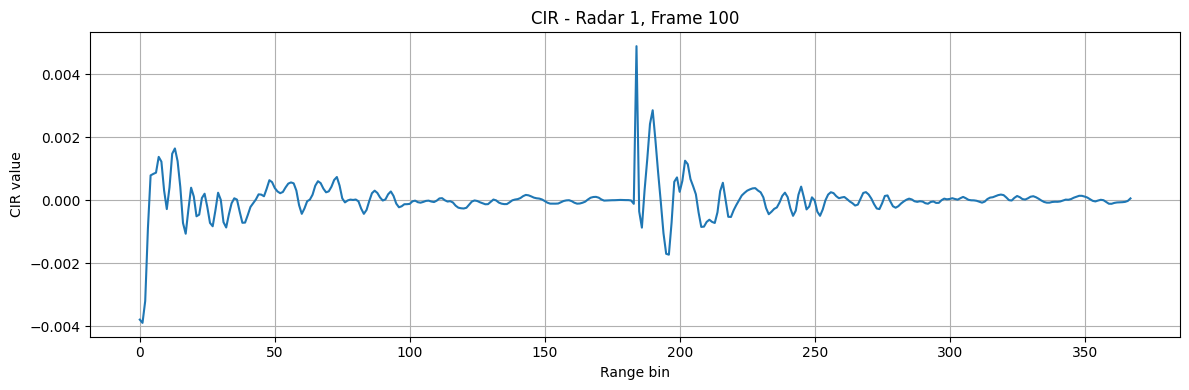

In [7]:
radar_idx = 0
frame_idx = 100

frame = cir[radar_idx, frame_idx, :]

plt.figure(figsize=(12, 4))
plt.plot(np.arange(368), frame)

plt.xlabel("Range bin")
plt.ylabel("CIR value")
plt.title(f"CIR - Radar {radar_idx + 1}, Frame {frame_idx}")

plt.grid(True)
plt.tight_layout()
plt.show()

## 4. Kiểm tra các sự kiện té ngã đã được gắn nhãn

Kiểm tra các nhãn sự kiện trước khi phân tích sự biến thiên của tín hiệu CIR.

In [8]:
import pandas as pd

events = pd.read_csv("../streams_events.csv")

print("Kích thước bảng sự kiện:", events.shape)
print("\nTên các cột:")
print(events.columns.tolist())

display(events.head())

Kích thước bảng sự kiện: (478, 12)

Tên các cột:
['stream_id', 'event_id', 't_start', 't_end', 'fall_type', 'ignore', 'quality', 'needs_review', 'source_path', 'source_t_start', 'source_t_end', 'dataset']


,stream_id,event_id,t_start,t_end,fall_type,ignore,quality,needs_review,source_path,source_t_start,source_t_end,dataset
0,train_00,train_00_0017,193.52,195.58,Chute03,False,normal,False,falls/Dataset 3/Test_P3_3/Chute03_152.json,4.50,6.56,Dataset 3
1,train_00,train_00_0020,231.42,233.02,Chute01,False,normal,False,falls/Dataset 3/Test_P3_3/Chute01_152.json,3.28,4.88,Dataset 3
2,train_00,train_00_0021,241.36,243.36,Chute01,False,normal,False,falls/Dataset 2/Test_P2_7/Chute01_211.json,2.82,4.82,Dataset 2
3,train_00,train_00_0026,292.96,294.68,Chute03,False,normal,False,falls/Dataset 1/Test_P1_7/Chute03_231.json,2.50,4.22,Dataset 1
4,train_00,train_00_0030,326.90,327.58,Chute04,False,normal,True,falls/Dataset 2/Test_P2_2/Chute04_00000003.json,2.88,3.56,Dataset 2


In [9]:
# Lọc các sự kiện thuộc stream validation đầu tiên
val_events = events[events["stream_id"] == "val_00"].copy()

print("Số sự kiện trong val_00:", len(val_events))

display(
    val_events[
        ["stream_id", "event_id", "t_start", "t_end",
         "fall_type", "ignore", "quality", "needs_review"]
    ].head(10)
)

Số sự kiện trong val_00: 34


,stream_id,event_id,t_start,t_end,fall_type,ignore,quality,needs_review
359,val_00,val_00_0002,28.34,29.12,Chute02,False,normal,True
360,val_00,val_00_0003,37.90,39.90,Chute01,False,normal,False
361,val_00,val_00_0004,50.52,52.52,Chute04,False,normal,False
362,val_00,val_00_0007,89.06,92.00,Chute03,False,low,False
363,val_00,val_00_0011,125.28,127.26,Chute04,False,normal,False
364,val_00,val_00_0015,173.00,174.58,Chute01,False,normal,False
365,val_00,val_00_0017,195.28,197.42,Chute04,False,normal,True
366,val_00,val_00_0024,273.92,275.28,Chute02,False,normal,False
367,val_00,val_00_0030,340.12,341.14,Chute03,False,normal,False
368,val_00,val_00_0039,467.68,469.24,Chute01,False,normal,False


In [10]:
# Chọn các sự kiện có chất lượng normal và không cần xem xét lại
reliable_events = val_events[
    (val_events["needs_review"] == False) &
    (val_events["quality"] == "normal") &
    (val_events["ignore"] == False)
].copy()

print("Số sự kiện phù hợp:", len(reliable_events))

display(
    reliable_events[
        ["stream_id", "event_id", "t_start", "t_end",
         "fall_type", "quality", "needs_review"]
    ].head(10)
)

Số sự kiện phù hợp: 21


,stream_id,event_id,t_start,t_end,fall_type,quality,needs_review
360,val_00,val_00_0003,37.90,39.90,Chute01,normal,False
361,val_00,val_00_0004,50.52,52.52,Chute04,normal,False
363,val_00,val_00_0011,125.28,127.26,Chute04,normal,False
364,val_00,val_00_0015,173.00,174.58,Chute01,normal,False
366,val_00,val_00_0024,273.92,275.28,Chute02,normal,False
367,val_00,val_00_0030,340.12,341.14,Chute03,normal,False
368,val_00,val_00_0039,467.68,469.24,Chute01,normal,False
370,val_00,val_00_0046,549.26,550.94,Chute03,normal,False
375,val_00,val_00_0068,807.72,810.46,Chute01,normal,False
376,val_00,val_00_0069,818.70,820.78,Chute03,normal,False


## 5. Motion Energy

Motion Energy được tính một lần cho toàn bộ luồng tín hiệu (*stream*). Các khoảng thời gian trước và sau sự kiện được xác định bằng cửa sổ 5 giây, trong khi khoảng thời gian diễn ra sự kiện được xác định dựa trên nhãn `t_start`–`t_end`.

In [11]:
# 5. Tính Motion Energy một lần cho toàn bộ stream
# cir có shape (radar, frame, range_bin)
# Motion Energy = mean bình phương sai khác CIR giữa hai frame liên tiếp.

motion_energy_all = np.mean(np.diff(cir, axis=1) ** 2, axis=2)
energy_time = t[1:]  # thời điểm ứng với cặp frame liên tiếp
WIN = 5.0            # cửa sổ trước/sau sự kiện, tính bằng giây

print("Shape motion_energy_all:", motion_energy_all.shape)
print("Số thời điểm:", len(energy_time))
print(f"Cửa sổ trước/sau sự kiện: {WIN:.1f} giây")


Shape motion_energy_all: (3, 88188)
Số thời điểm: 88188
Cửa sổ trước/sau sự kiện: 5.0 giây


## 6. Case study: val_00_0046
Xem bảng ba giai đoạn, chuỗi thời gian Motion Energy và heatmap CIR đã trừ n

In [12]:
# 6. Case study: val_00_0046
EVENT_ID = "val_00_0046"

event_rows = reliable_events[reliable_events["event_id"] == EVENT_ID]
if event_rows.empty:
    raise ValueError(f"Không tìm thấy {EVENT_ID} trong reliable_events")
ev = event_rows.iloc[0]
ev_start, ev_end = float(ev["t_start"]), float(ev["t_end"])
print(EVENT_ID, ev["fall_type"], f"{ev_start:.3f}-{ev_end:.3f} s")

masks = {
    "Trước": (energy_time >= ev_start - WIN) & (energy_time < ev_start),
    "Trong": (energy_time >= ev_start) & (energy_time <= ev_end),
    "Sau": (energy_time > ev_end) & (energy_time <= ev_end + WIN),
}

rows = []
for r in range(cir.shape[0]):
    row = {"radar_idx": r, "Radar": r + 1, "Serial": int(radar_serials[r])}
    for phase, mask in masks.items():
        vals = motion_energy_all[r, mask]
        row[phase] = float(np.median(vals)) if len(vals) else np.nan
    row["Trong/Trước"] = row["Trong"] / row["Trước"] if pd.notna(row["Trước"]) and row["Trước"] > 0 else np.nan
    row["Sau/Trước"] = row["Sau"] / row["Trước"] if pd.notna(row["Trước"]) and row["Trước"] > 0 else np.nan
    rows.append(row)

comparison_df = pd.DataFrame(rows)
display(comparison_df)


val_00_0046 Chute03 549.260-550.940 s


,radar_idx,Radar,Serial,Trước,Trong,Sau,Trong/Trước,Sau/Trước
0,0,1,29171,2.116700e-10,1.840210e-10,1.833166e-10,0.869377,0.866049
1,1,2,29444,6.374185e-09,5.846465e-08,4.661540e-10,9.172098,0.073132
2,2,3,30722,9.927357e-10,7.301093e-10,3.888478e-10,0.735452,0.391693


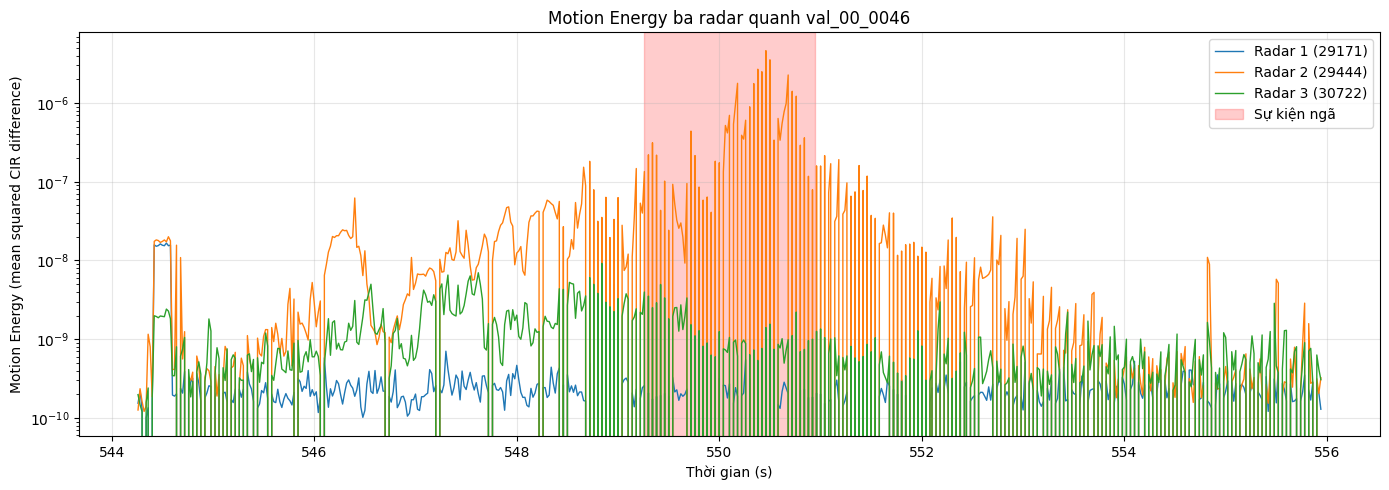

In [13]:
# Motion Energy quanh sự kiện đã chọn
fig, ax = plt.subplots(figsize=(14, 5))
sel = (energy_time >= ev_start - WIN) & (energy_time <= ev_end + WIN)
for r in range(cir.shape[0]):
    ax.plot(energy_time[sel], motion_energy_all[r, sel],
            label=f"Radar {r+1} ({radar_serials[r]})", lw=1)
ax.axvspan(ev_start, ev_end, color="red", alpha=0.2, label="Sự kiện ngã")
ax.set_yscale("log")
ax.set_xlabel("Thời gian (s)")
ax.set_ylabel("Motion Energy (mean squared CIR difference)")
ax.set_title(f"Motion Energy ba radar quanh {EVENT_ID}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


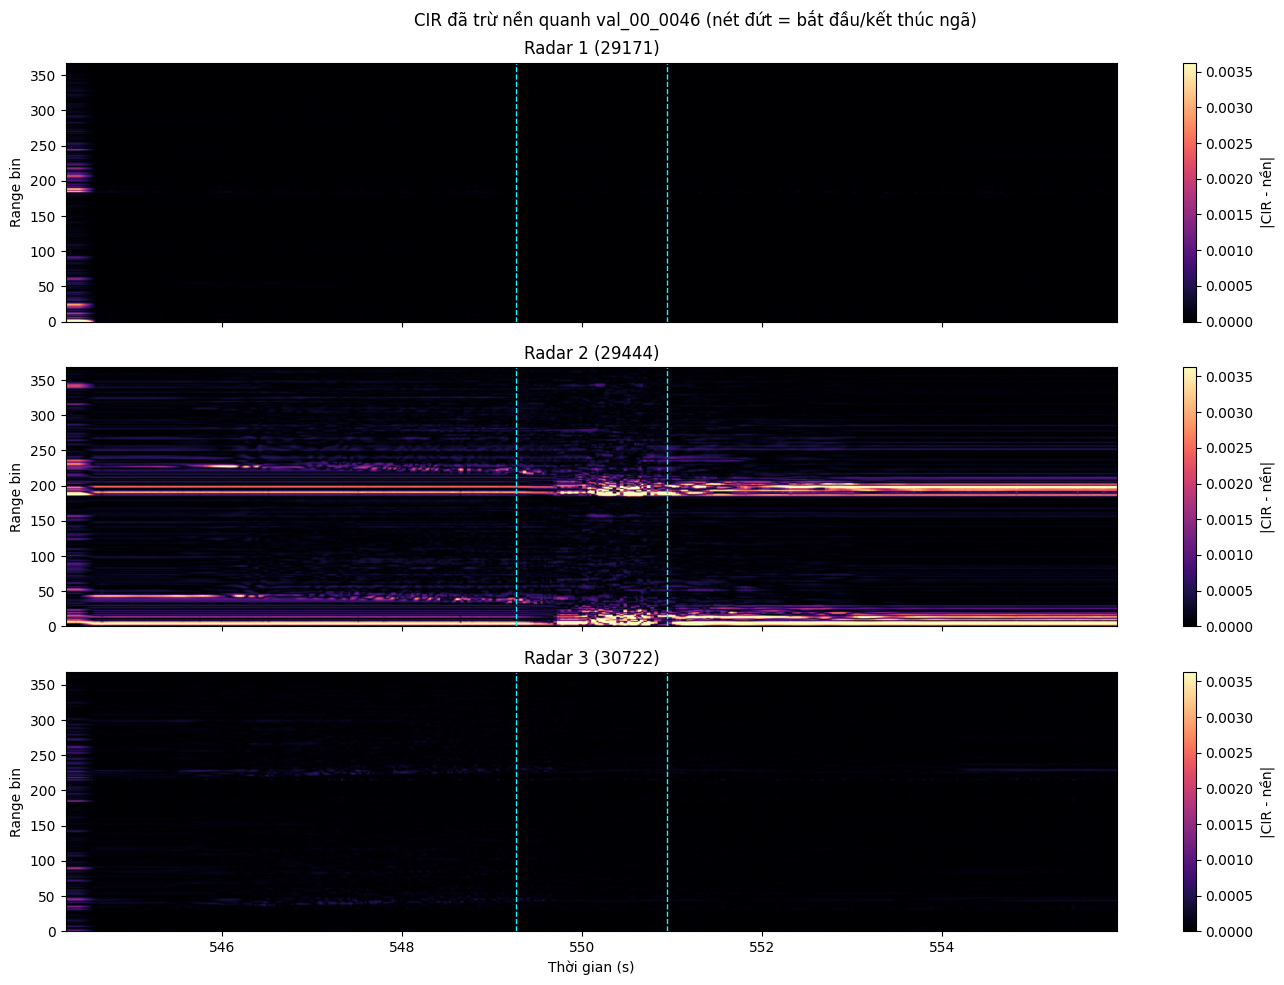

In [14]:
# Heatmap CIR quanh sự kiện, trừ nền theo từng range bin
idx = np.where((t >= ev_start - WIN) & (t <= ev_end + WIN))[0]
if len(idx) == 0:
    raise ValueError("Không có frame CIR trong cửa sổ sự kiện")
t_win = t[idx]

fig, axes = plt.subplots(cir.shape[0], 1, figsize=(14, 10), sharex=True)
if cir.shape[0] == 1:
    axes = [axes]
dyn = []
for r in range(cir.shape[0]):
    seg = cir[r, idx, :]
    background = np.median(seg, axis=0)
    dyn.append(np.abs(seg - background))
vmax = np.percentile(np.concatenate([d.ravel() for d in dyn]), 99.5)

for r, ax in enumerate(axes):
    im = ax.imshow(dyn[r].T, aspect="auto", origin="lower", cmap="magma",
                   vmin=0, vmax=vmax,
                   extent=[t_win[0], t_win[-1], 0, cir.shape[2]])
    ax.axvline(ev_start, color="cyan", linestyle="--", lw=1)
    ax.axvline(ev_end, color="cyan", linestyle="--", lw=1)
    ax.set_ylabel("Range bin")
    ax.set_title(f"Radar {r+1} ({radar_serials[r]})")
    fig.colorbar(im, ax=ax, label="|CIR - nền|")
axes[-1].set_xlabel("Thời gian (s)")
fig.suptitle(f"CIR đã trừ nền quanh {EVENT_ID} (nét đứt = bắt đầu/kết thúc ngã)")
plt.tight_layout()
plt.show()


### Nhận xét heatmap CIR quanh `val_00_0046`

Trên cùng thang màu của ba radar, **Radar 2 (`29444`) cho phản ứng rõ nhất**. Từ khoảng `549,7 s`, hai vùng sáng xuất hiện tại các range bin khoảng `190–200` và `0–15`, với cường độ mạnh nhất trong khoảng `549,7–551 s`.

Khác với Motion Energy, các dải tín hiệu này không biến mất sau sự kiện mà tiếp tục duy trì đến hết cửa sổ quan sát. Điều này cho thấy trạng thái tín hiệu sau khi ngã khác với trạng thái trước khi ngã. Kết quả này phù hợp với việc Motion Energy giảm mạnh sau sự kiện: chuyển động giảm, nhưng tín hiệu CIR vẫn lệch so với nền.

Trong khi đó, **Radar 1 và Radar 3 gần như không ghi nhận thay đổi rõ rệt** trên cùng thang màu.

Đây mới chỉ là quan sát trên một sự kiện, vì vậy chưa đủ cơ sở để đưa ra kết luận tổng quát.

- Ở đầu cửa sổ quan sát (khoảng `544,3–544,6 s`), cả ba radar đều xuất hiện vệt sáng dọc trên heatmap và một đỉnh trên đồ thị Motion Energy. Do hiện tượng xảy ra đồng thời trên cả ba radar và cách xa thời điểm ngã được gắn nhãn, đây có thể là nhiễu hoặc hiện tượng chuyển tiếp của dữ liệu, thay vì phản ứng liên quan trực tiếp đến sự kiện ngã.

- Motion Energy của Radar 2 bắt đầu tăng từ khoảng `548,5 s`, sớm hơn thời điểm `t_start` (`549,26 s`). Vì vậy, cửa sổ **5 giây trước sự kiện** có thể đã bao gồm chuyển động ngay trước khi ngã. Do đó, tỷ lệ Motion Energy giữa khoảng Trong và Trước có thể phụ thuộc vào cách xác định các cửa sổ thời gian.

- Các điểm giảm xuống đáy trên đồ thị log tương ứng với những cặp frame liên tiếp có tín hiệu giống hệt nhau, khiến hiệu giữa chúng bằng `0`. Điều này không đồng nghĩa với việc tín hiệu thực sự không có hoạt động. Vấn đề này sẽ được xử lý riêng trong **Mục 10**.

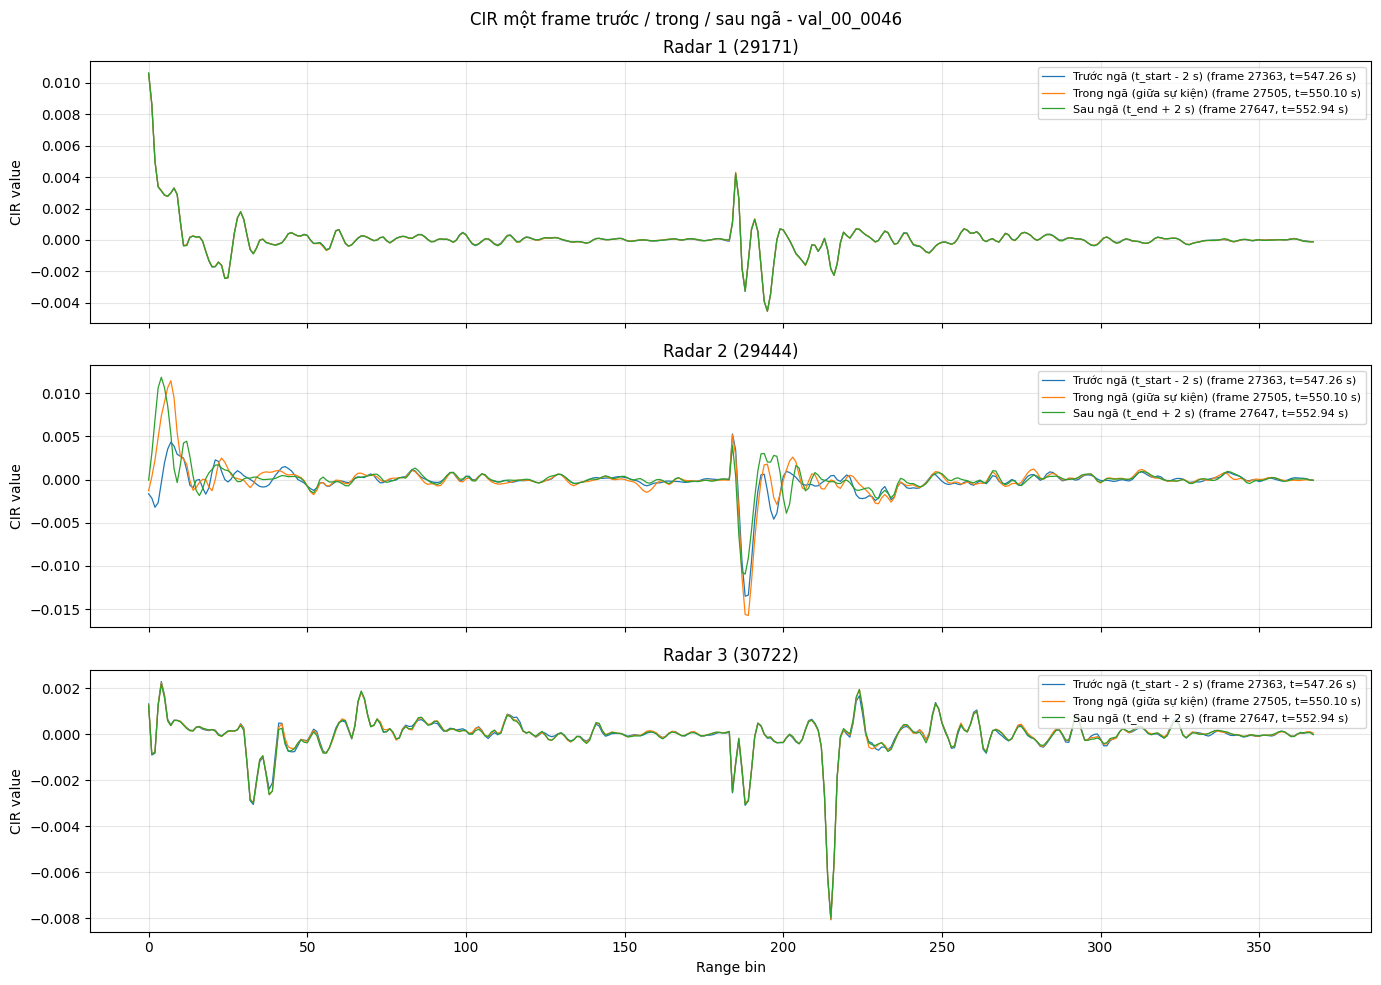

In [15]:
# CIR của một frame đại diện cho từng giai đoạn (val_00_0046), mỗi ô là một radar
phase_times = {
    "Trước ngã (t_start - 2 s)": ev_start - 2.0,
    "Trong ngã (giữa sự kiện)": (ev_start + ev_end) / 2,
    "Sau ngã (t_end + 2 s)": ev_end + 2.0,
}
phase_frames = {name: int(np.argmin(np.abs(t - tt))) for name, tt in phase_times.items()}

fig, axes = plt.subplots(cir.shape[0], 1, figsize=(14, 10), sharex=True)
for r, ax in enumerate(axes):
    for name, fi in phase_frames.items():
        ax.plot(np.arange(cir.shape[2]), cir[r, fi, :], lw=0.9, label=f"{name} (frame {fi}, t={t[fi]:.2f} s)")
    ax.set_ylabel("CIR value")
    ax.set_title(f"Radar {r+1} ({radar_serials[r]})")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Range bin")
fig.suptitle(f"CIR một frame trước / trong / sau ngã - {EVENT_ID}")
plt.tight_layout()
plt.show()

Biểu đồ trên đặt ba frame đại diện (trước, trong, sau ngã) lên cùng một trục cho từng radar, để so sánh hình dạng CIR theo range bin giữa các giai đoạn và giữa các radar.

## 7. Tổng hợp các sự kiện đáng tin cậy
So sánh median Motion Energy trước, trong và sau sự kiện trên ba radar.

Số sự kiện đáng tin cậy: 21
Số sự kiện có đủ dữ liệu cho cả ba giai đoạn: 21


,event_id,fall_type,radar_idx,radar_serial,before_energy,during_energy,after_energy,energy_ratio,after_before_ratio
0,val_00_0003,Chute01,0,29171,2.511348e-10,7.183391e-10,1.225004e-10,2.860373,0.487787
1,val_00_0003,Chute01,1,29444,4.229235e-10,3.874274e-09,1.490706e-10,9.160697,0.352477
2,val_00_0003,Chute01,2,30722,7.258998e-10,1.986026e-07,2.275110e-10,273.595115,0.313419
3,val_00_0004,Chute04,0,29171,1.715924e-10,2.009422e-10,1.890527e-10,1.171044,1.101755
4,val_00_0004,Chute04,1,29444,1.873434e-10,2.847146e-08,3.119429e-08,151.974724,166.508653


,radar_idx,radar_serial,n_events,median_before,median_during,median_after,median_during_before,median_after_before,pct_during_higher,pct_after_higher
0,0,29171,21,2.141650e-10,2.946549e-10,1.661692e-10,1.201327,0.821771,61.904762,42.857143
1,1,29444,21,4.111578e-10,1.391629e-08,2.382479e-10,12.072893,0.352477,85.714286,23.809524
2,2,30722,21,6.017447e-10,4.819346e-08,4.093081e-10,24.286545,0.664459,85.714286,38.095238


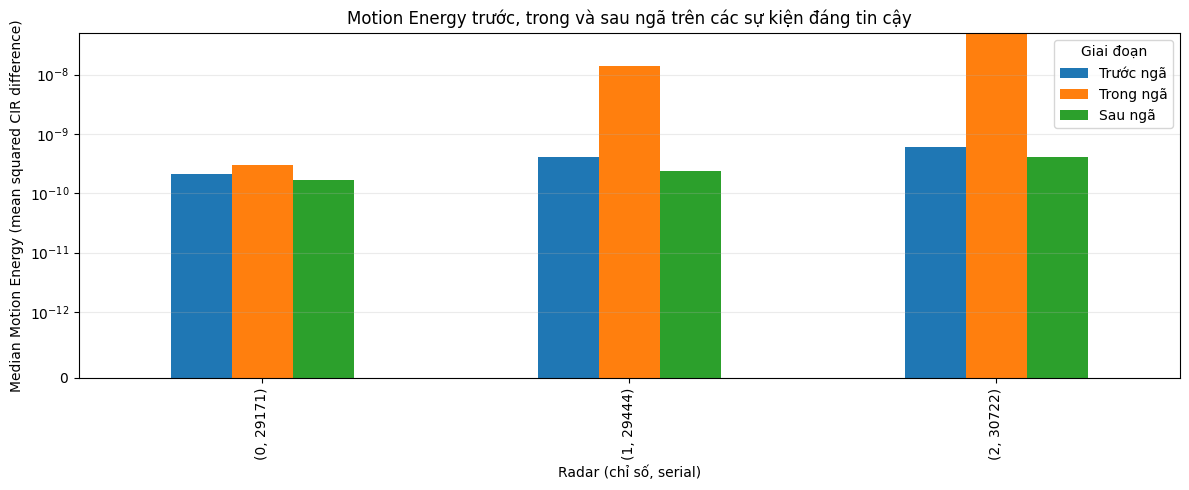

In [16]:
# 7. Tổng hợp 21 sự kiện đáng tin cậy theo radar
# Mỗi sự kiện/radar: lấy median riêng cho trước, trong và sau sự kiện.
rows = []
for _, event in reliable_events.iterrows():
    event_start = float(event["t_start"])
    event_end = float(event["t_end"])
    phase_masks = {
        "before_energy": (energy_time >= event_start - WIN) & (energy_time < event_start),
        "during_energy": (energy_time >= event_start) & (energy_time <= event_end),
        "after_energy": (energy_time > event_end) & (energy_time <= event_end + WIN),
    }
    # Bỏ qua sự kiện nếu bất kỳ giai đoạn nào không có dữ liệu.
    if not all(mask.any() for mask in phase_masks.values()):
        continue
    for r in range(cir.shape[0]):
        row = {
            "event_id": event["event_id"],
            "fall_type": event["fall_type"],
            "radar_idx": r,
            "radar_serial": int(radar_serials[r]),
        }
        for col, mask in phase_masks.items():
            row[col] = float(np.median(motion_energy_all[r, mask]))
        row["energy_ratio"] = row["during_energy"] / row["before_energy"] if row["before_energy"] > 0 else np.nan
        row["after_before_ratio"] = row["after_energy"] / row["before_energy"] if row["before_energy"] > 0 else np.nan
        rows.append(row)

results_df = pd.DataFrame(rows)
print("Số sự kiện đáng tin cậy:", reliable_events["event_id"].nunique())
print("Số sự kiện có đủ dữ liệu cho cả ba giai đoạn:", results_df["event_id"].nunique() if not results_df.empty else 0)
display(results_df.head())

summary = results_df.groupby(["radar_idx", "radar_serial"]).agg(
    n_events=("event_id", "nunique"),
    median_before=("before_energy", "median"),
    median_during=("during_energy", "median"),
    median_after=("after_energy", "median"),
    median_during_before=("energy_ratio", "median"),
    median_after_before=("after_before_ratio", "median"),
).reset_index()

valid_during = results_df.dropna(subset=["energy_ratio"])
pct_during = valid_during.assign(higher=valid_during["energy_ratio"] > 1).groupby("radar_idx")["higher"].mean().mul(100)
valid_after = results_df.dropna(subset=["after_before_ratio"])
pct_after = valid_after.assign(higher=valid_after["after_before_ratio"] > 1).groupby("radar_idx")["higher"].mean().mul(100)
summary["pct_during_higher"] = summary["radar_idx"].map(pct_during)
summary["pct_after_higher"] = summary["radar_idx"].map(pct_after)
display(summary)

# Biểu đồ median Motion Energy theo ba giai đoạn
phase_summary = results_df.groupby(["radar_idx", "radar_serial"])[
    ["before_energy", "during_energy", "after_energy"]
].median()
phase_summary.columns = ["Trước ngã", "Trong ngã", "Sau ngã"]
ax = phase_summary.plot(kind="bar", figsize=(12, 5), yerr=None)
ax.set_title("Motion Energy trước, trong và sau ngã trên các sự kiện đáng tin cậy")
ax.set_xlabel("Radar (chỉ số, serial)")
ax.set_ylabel("Median Motion Energy (mean squared CIR difference)")
ax.set_yscale("symlog", linthresh=1e-12)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Giai đoạn")
plt.tight_layout()
plt.show()


In [17]:
# 8. Kiểm tra tỷ lệ Motion Energy của từng sự kiện
if results_df.empty:
    raise ValueError("results_df rỗng; kiểm tra reliable_events và các khoảng thời gian")
event_comparison = results_df.pivot(
    index="event_id", columns="radar_idx", values="energy_ratio"
)
event_comparison = event_comparison.rename(columns={0: "Radar 1", 1: "Radar 2", 2: "Radar 3"})
event_comparison["Highest ratio"] = event_comparison[["Radar 1", "Radar 2", "Radar 3"]].max(axis=1, skipna=True)
display(event_comparison)


radar_idx,Radar 1,Radar 2,Radar 3,Highest ratio
event_id,,,,
val_00_0003,2.860373,9.160697,273.595115,273.595115
val_00_0004,1.171044,151.974724,2.373715,151.974724
val_00_0011,1.127889,4.560734,2.009232,4.560734
val_00_0015,1.201327,74.073024,5.432263,74.073024
val_00_0024,0.884623,12.072893,0.925122,12.072893
val_00_0030,0.718088,37.004950,0.333033,37.004950
val_00_0039,0.246484,0.712201,131.908127,131.908127
val_00_0046,0.869377,9.172098,0.735452,9.172098
val_00_0068,1.785996,113.833968,20.938197,113.833968


In [18]:
# 9. Tỷ lệ sự kiện có Motion Energy tăng so với trước
radar_cols = ["Radar 1", "Radar 2", "Radar 3"]
increase_counts = (event_comparison[radar_cols] > 1).sum()
total_events = event_comparison[radar_cols].count()
increase_summary = pd.DataFrame({
    "Số sự kiện có tỷ lệ > 1": increase_counts,
    "Số sự kiện có dữ liệu": total_events,
    "Tỷ lệ sự kiện tăng (%)": (increase_counts / total_events * 100).round(2),
})
display(increase_summary)


,Số sự kiện có tỷ lệ > 1,Số sự kiện có dữ liệu,Tỷ lệ sự kiện tăng (%)
radar_idx,,,
Radar 1,13,21,61.90
Radar 2,18,21,85.71
Radar 3,18,21,85.71


## 8. Kiểm tra lại sau khi loại các bước frame trùng
Khoảng 26% frame trùng hệt frame trước (mục 2), làm Motion Energy của các bước đó bằng 0. Mục này bỏ các bước đó rồi tính lại đồ thị và tỷ lệ Trong/Trước, Sau/Trước để kiểm tra kết quả có ổn định hay không.

Tỷ lệ bước trùng theo radar: [0.266 0.262 0.265]


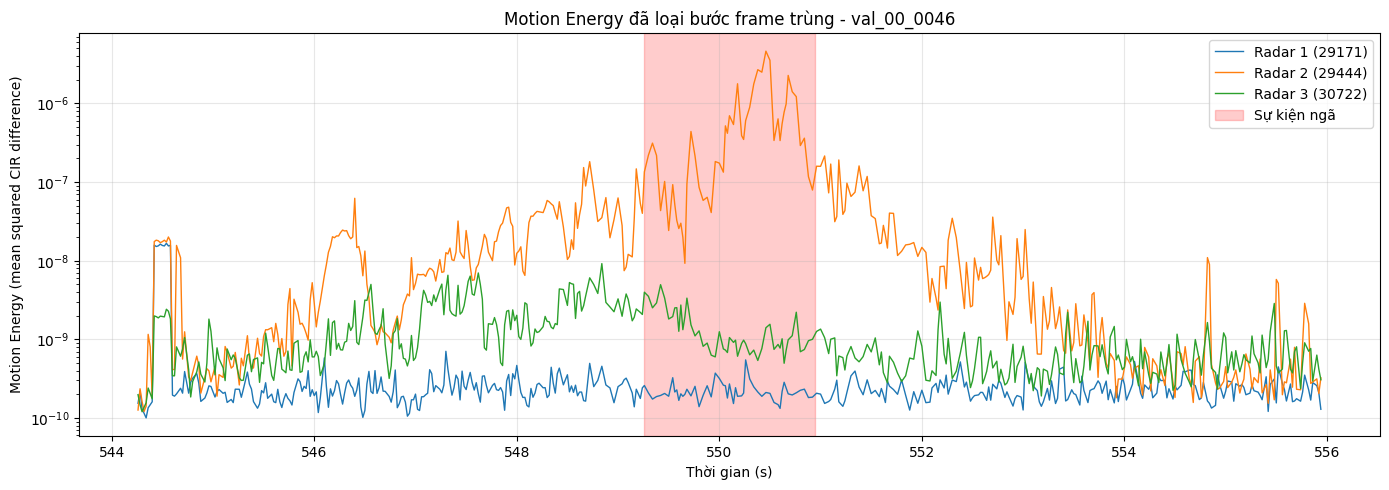

In [19]:
# Motion Energy sau khi loại các bước hai frame trùng hệt nhau
dup_step = np.zeros(motion_energy_all.shape, dtype=bool)
for r in range(cir.shape[0]):          # lặp từng radar để tiết kiệm bộ nhớ
    dup_step[r] = np.all(np.diff(cir[r], axis=0) == 0, axis=1)
print("Tỷ lệ bước trùng theo radar:", np.round(dup_step.mean(axis=1), 3))

sel = (energy_time >= ev_start - WIN) & (energy_time <= ev_end + WIN)
fig, ax = plt.subplots(figsize=(14, 5))
for r in range(cir.shape[0]):
    m = sel & ~dup_step[r]
    ax.plot(energy_time[m], motion_energy_all[r, m], lw=1, label=f"Radar {r+1} ({radar_serials[r]})")
ax.axvspan(ev_start, ev_end, color="red", alpha=0.2, label="Sự kiện ngã")
ax.set_yscale("log")
ax.set_xlabel("Thời gian (s)")
ax.set_ylabel("Motion Energy (mean squared CIR difference)")
ax.set_title(f"Motion Energy đã loại bước frame trùng - {EVENT_ID}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Tính lại tỷ lệ Trong/Trước và Sau/Trước trên 21 sự kiện, bỏ các bước frame trùng
rows = []
for _, event in reliable_events.iterrows():
    s, e = float(event["t_start"]), float(event["t_end"])
    masks = {
        "before": (energy_time >= s - WIN) & (energy_time < s),
        "during": (energy_time >= s) & (energy_time <= e),
        "after": (energy_time > e) & (energy_time <= e + WIN),
    }
    for r in range(cir.shape[0]):
        med = {}
        for phase, m in masks.items():
            v = motion_energy_all[r, m & ~dup_step[r]]
            med[phase] = float(np.median(v)) if len(v) else np.nan
        ok = pd.notna(med["before"]) and med["before"] > 0
        rows.append({
            "event_id": event["event_id"], "radar": r + 1, "serial": int(radar_serials[r]),
            "during_before": med["during"] / med["before"] if ok else np.nan,
            "after_before": med["after"] / med["before"] if ok else np.nan,
        })
clean_df = pd.DataFrame(rows)

summary_clean = clean_df.groupby(["radar", "serial"]).agg(
    n_events=("event_id", "nunique"),
    median_during_before=("during_before", "median"),
    median_after_before=("after_before", "median"),
    pct_during_higher=("during_before", lambda x: (x.dropna() > 1).mean() * 100),
    pct_after_higher=("after_before", lambda x: (x.dropna() > 1).mean() * 100),
).reset_index()
display(summary_clean)

# Radar có tỷ lệ Trong/Trước cao nhất ở từng sự kiện
best = clean_df.pivot(index="event_id", columns="radar", values="during_before").dropna(how="all").idxmax(axis=1)
print("Số sự kiện mà mỗi radar có tỷ lệ Trong/Trước cao nhất:")
print(best.value_counts().sort_index())

,radar,serial,n_events,median_during_before,median_after_before,pct_during_higher,pct_after_higher
0,1,29171,21,1.034374,0.921816,61.904762,42.857143
1,2,29444,21,17.378705,0.184415,80.952381,28.571429
2,3,30722,21,20.890636,0.812849,90.476190,42.857143


Số sự kiện mà mỗi radar có tỷ lệ Trong/Trước cao nhất:
2    10
3    11
Name: count, dtype: int64


## Nhận xét đặc điểm tín hiệu và so sánh ba radar

**1. Đặc điểm tín hiệu quanh thời điểm ngã (case study val_00_0046, Chute03, 549,26–550,94 s).**
Radar 2 (29444) phản ứng rõ nhất. Median Motion Energy tăng từ 6,4e-9 (trước) lên 5,8e-8 (trong), tỷ lệ Trong/Trước khoảng 9,2. Radar 1 (tỷ lệ 0,87) và Radar 3 (0,74) gần như không tăng trong sự kiện này. Trên heatmap đã trừ nền, Radar 2 xuất hiện các vùng sáng quanh range bin 190–200 và 0–15, mạnh nhất khoảng 549,7–551 s và kéo dài đến hết cửa sổ quan sát. Sau ngã, Motion Energy của Radar 2 giảm còn khoảng 0,07 lần so với trước ngã (không còn chuyển động mạnh), trong khi CIR vẫn lệch khỏi nền, tức trạng thái tín hiệu sau ngã khác trạng thái trước ngã.

**2. Trước, trong và sau ngã trên 21 sự kiện đáng tin cậy (median theo từng sự kiện).**

| Radar | Trong/Trước | % sự kiện Trong > Trước | Sau/Trước | % sự kiện Sau > Trước |
|---|---|---|---|---|
| 1 (29171) | 1,20 | 61,9% (13/21) | 0,82 | 42,9% |
| 2 (29444) | 12,07 | 85,7% (18/21) | 0,35 | 23,8% |
| 3 (30722) | 24,29 | 85,7% (18/21) | 0,66 | 38,1% |

Motion Energy thường tăng rõ trong khoảng ngã rồi giảm sau đó, rõ nhất ở Radar 2 và Radar 3. Ở Radar 1 mức tăng nhỏ và không ổn định giữa các sự kiện.

**3. Khác biệt giữa ba radar.**
- Radar 2 và Radar 3 nhạy với chuyển động ngã hơn Radar 1 (median Trong/Trước lần lượt 12,1 và 24,3 so với 1,2).
- Xét radar có tỷ lệ cao nhất ở từng sự kiện: Radar 3 dẫn ở 11 sự kiện, Radar 2 ở 10, Radar 1 ở 0. Không radar nào tốt nhất trong mọi trường hợp, nên kết hợp nhiều radar có lợi hơn dùng một radar.
- Tỷ lệ Trong/Trước dao động rất lớn giữa các sự kiện (từ khoảng 0,2 đến hơn 3.400), nên cần dùng median và số sự kiện thay vì giá trị trung bình.

**4. Giới hạn.** Motion Energy chỉ mô tả mức biến thiên tín hiệu, không phải bộ phân loại ngã; chuyển động thường ngày cũng làm chỉ số tăng. Phân tích mới dùng một stream (val_00), chưa so với các đoạn không ngã, và cửa sổ "trước" có thể chứa chuyển động ngay trước nhãn ngã. Mục 10 là phép kiểm tra lại sau khi loại các bước frame trùng.

## Kết luận

Notebook khảo sát tín hiệu CIR (368 range bins) của ba radar trên stream val_00: kiểm tra lưới thời gian 50 Hz và các frame trùng, trực quan hóa CIR theo range bin và theo thời gian, rồi dùng Motion Energy để mô tả biến thiên giữa các frame quanh các sự kiện ngã.

- Trên 21 sự kiện đáng tin cậy, Motion Energy trong khoảng ngã cao hơn trước ngã ở 18/21 sự kiện với Radar 2 và Radar 3, và 13/21 với Radar 1.
- Radar 2 và Radar 3 phản ứng mạnh hơn Radar 1; radar phản ứng mạnh nhất thay đổi theo từng sự kiện.
- Sau ngã, Motion Energy thường giảm, nhưng CIR có thể vẫn lệch khỏi nền (case study val_00_0046).

Giới hạn: chỉ một stream validation, chưa so với đoạn không ngã, và Motion Energy chưa phải đánh giá hiệu năng của hệ thống phát hiện ngã. Đây là phân tích thăm dò đặc điểm tín hiệu.